# Hybrid Stacking Model — Built From Scratch
### Companion notebook to `Paddy_Yield_Prediction.ipynb` · Group 2 · B1_Sec_A_Sem_V

In the main notebook we used **scikit-learn** to build the hybrid model in one line (`StackingRegressor(...)`).
That works, but a teacher can ask: *"What is actually happening inside that box?"*

In this notebook we **write every piece ourselves using only NumPy**, then check that our hand-made version gives (almost) the same result as scikit-learn.

### What we will build, in order
| # | Piece | Why we need it |
|---|---|---|
| 1 | Train / test split | to keep hidden data for testing |
| 2 | Evaluation metrics (R², MAE, RMSE, MAPE) | to measure how good a model is |
| 3 | **Linear Regression** | simplest model; also used as the *meta model* |
| 4 | **Positive Linear Regression** | the meta model of our hybrid (weights can't be negative) |
| 5 | **Decision Tree Regressor** | the building block of Random Forest and Gradient Boosting |
| 6 | **Random Forest Regressor** | many trees averaged together → stable |
| 7 | **Gradient Boosting Regressor** | trees that fix each other's mistakes → accurate |
| 8 | **K-Fold** | to create "unseen" predictions for stacking |
| 9 | **Stacking Regressor (our Hybrid)** | combines 3 base models with a meta model |
| 10 | Comparison with scikit-learn | proof that our code is correct |

**Rule for this notebook:** pandas is only used to *load* the CSV. All the machine-learning maths is plain **NumPy** (arrays, sums, sorting).

---
## Part 0 · Load and prepare the data
This is the **same cleaning** as the main notebook (Steps 3 & 5 there):
1. strip extra spaces from column names and text values,
2. remove the 451 duplicate rows,
3. keep the 5 optimized features: `Hectares, Agriblock, Variety, Soil, Nursery`,
4. one-hot encode the text columns (turn words into 0/1 columns).

At the end we convert everything to **NumPy arrays** `X` (inputs) and `y` (yield), because our hand-made models work on arrays.

In [1]:
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd

df = pd.read_csv("paddydataset.csv")
df.columns = df.columns.str.strip()
df = df.rename(columns={"Soil Types": "Soil", "Paddy yield(in Kg)": "Yield"})
for col in df.select_dtypes("object").columns:
    df[col] = df[col].str.strip()
df = df.drop_duplicates().reset_index(drop=True)

features = ["Hectares", "Agriblock", "Variety", "Soil", "Nursery"]
X_df = pd.get_dummies(df[features], dtype=int)

X = X_df.to_numpy(dtype=float)        # shape (rows, 14)
y = df["Yield"].to_numpy(dtype=float) # shape (rows,)
feature_names = list(X_df.columns)

print("X shape:", X.shape, "| y shape:", y.shape)
print("Columns:", feature_names)

X shape: (2338, 14) | y shape: (2338,)
Columns: ['Hectares', 'Agriblock_Chinnasalem', 'Agriblock_Cuddalore', 'Agriblock_Kallakurichi', 'Agriblock_Kurinjipadi', 'Agriblock_Panruti', 'Agriblock_Sankarapuram', 'Variety_CO_43', 'Variety_delux ponni', 'Variety_ponmani', 'Soil_alluvial', 'Soil_clay', 'Nursery_dry', 'Nursery_wet']


---
## Part 1 · Train / test split (from scratch)

**Idea:** shuffle the row numbers randomly, then
- the **first 20%** of the shuffled rows → **test set** (hidden, used only at the end),
- the **remaining 80%** → **training set** (the model learns from these).

`np.random.RandomState(42)` is a random-number generator with a fixed **seed** (42).
A fixed seed means "random, but the same every time we run" → results are reproducible.

> We use exactly the same recipe that scikit-learn's `train_test_split(test_size=0.2, random_state=42)` uses internally, so we get the **exact same rows** as in the main notebook. This lets us compare fairly.

In [2]:
def my_train_test_split(n_rows, test_size=0.2, seed=42):
    rng = np.random.RandomState(seed)
    shuffled = rng.permutation(n_rows)              # e.g. [17, 3, 2200, 5, ...]
    n_test = int(np.ceil(test_size * n_rows))       # 20% of 2338 = 467.6 → 468
    test_idx = shuffled[:n_test]
    train_idx = shuffled[n_test:]
    return train_idx, test_idx

train_idx, test_idx = my_train_test_split(len(y))
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print("Training rows:", len(train_idx), "| Testing rows:", len(test_idx))

Training rows: 1870 | Testing rows: 468


**Check:** does our split match scikit-learn's? (We use scikit-learn here *only* to verify.)

In [3]:
from sklearn.model_selection import train_test_split
sk_train, sk_test = train_test_split(np.arange(len(y)), test_size=0.2, random_state=42)
print("Same test rows as scikit-learn?    ", np.array_equal(np.sort(sk_test), np.sort(test_idx)))
print("Same training rows as scikit-learn?", np.array_equal(np.sort(sk_train), np.sort(train_idx)))

Same test rows as scikit-learn?     True
Same training rows as scikit-learn? True


---
## Part 2 · Evaluation metrics (from scratch)

Let **yᵢ** = actual yield, **ŷᵢ** ("y-hat") = predicted yield, **n** = number of rows, **ȳ** = average of actual yields.

| Metric | Formula | In plain words |
|---|---|---|
| **MAE** (Mean Absolute Error) | (1/n) · Σ \|yᵢ − ŷᵢ\| | on average, how many kg are we wrong by? |
| **RMSE** (Root Mean Squared Error) | √[ (1/n) · Σ (yᵢ − ŷᵢ)² ] | like MAE, but big mistakes count extra (because they are squared) |
| **MAPE** (Mean Absolute % Error) | (100/n) · Σ \|yᵢ − ŷᵢ\| / yᵢ | on average, how many **percent** are we wrong by? |
| **R²** (R-squared) | 1 − Σ(yᵢ − ŷᵢ)² / Σ(yᵢ − ȳ)² | how much better are we than just guessing the average every time? |

### Understanding R² with a tiny example
- Suppose the actual yields are **10, 20, 30** → the average ȳ = 20.
- A "lazy model" that always predicts 20 makes squared errors (10−20)² + (20−20)² + (30−20)² = **200**. This is the bottom part of the formula.
- Our model predicts **11, 19, 31** → squared errors 1 + 1 + 1 = **3**. This is the top part.
- R² = 1 − 3/200 = **0.985** → our model removes 98.5% of the lazy model's error.
- R² = 1 means perfect, R² = 0 means "no better than the average".

In [4]:
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mape(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred) / y_true) * 100

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)            # error of our model
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)     # error of the "always guess the average" model
    return 1 - ss_res / ss_tot

# the tiny example from above
toy_true, toy_pred = np.array([10., 20., 30.]), np.array([11., 19., 31.])
print("Tiny example →  R² =", round(r2(toy_true, toy_pred), 3), "| MAE =", mae(toy_true, toy_pred))

def report(name, y_true, y_pred):
    return {"Model": name, "R2": r2(y_true, y_pred), "MAE (kg)": mae(y_true, y_pred),
            "RMSE (kg)": rmse(y_true, y_pred), "MAPE (%)": mape(y_true, y_pred)}

Tiny example →  R² = 0.985 | MAE = 1.0


---
## Part 3 · Linear Regression (from scratch)

**Idea:** the prediction is a weighted sum of the inputs plus a constant:

> ŷ = **b** + w₁·x₁ + w₂·x₂ + … + w₁₄·x₁₄

- **w** = weights (one per column): how much each input pushes the yield up or down,
- **b** = intercept (bias): the starting value.

**How do we find the best w and b?** We want the weights that make the total squared error Σ(yᵢ − ŷᵢ)² as small as possible ("least squares").
There is a direct formula for this, the **Normal Equation**:

> **w = (XᵀX)⁻¹ Xᵀ y**

- We first add a column of 1s to X, so the intercept **b** is learned like any other weight.
- `Xᵀ` is X "transposed" (rows become columns), `⁻¹` is the matrix inverse.

**Why `pinv` (pseudo-inverse) instead of a normal inverse?**
Our one-hot columns are linked: for example `Soil_clay + Soil_alluvial = 1` on every row. Because of that, XᵀX has no normal inverse (it is a "singular" matrix).
The **pseudo-inverse** `np.linalg.pinv` still gives the best least-squares answer in this case. scikit-learn handles it the same way internally.

In [5]:
class MyLinearRegression:
    def fit(self, X, y):
        X1 = np.column_stack([np.ones(len(X)), X])      # add the column of 1s for the intercept
        w = np.linalg.pinv(X1.T @ X1) @ X1.T @ y         # Normal Equation:  w = (XᵀX)⁻¹ Xᵀ y
        self.intercept_, self.coef_ = w[0], w[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_          # ŷ = b + X·w

lin = MyLinearRegression().fit(X_train, y_train)
print("Intercept b =", round(lin.intercept_, 1))
print("Weight for Hectares =", round(lin.coef_[feature_names.index("Hectares")], 1),
      "→ each extra hectare adds about this many kg")
print("Test R² of our Linear Regression:", round(r2(y_test, lin.predict(X_test)), 4))

Intercept b = -436.9
Weight for Hectares = 6345.9 → each extra hectare adds about this many kg
Test R² of our Linear Regression: 0.9875


---
## Part 4 · Positive Linear Regression (our meta model)

In the hybrid model, the final step is a Linear Regression that combines the 3 base models' predictions:

> final = b + w₁·(prediction of model 1) + w₂·(prediction of model 2) + w₃·(prediction of model 3)

We want **w₁, w₂, w₃ ≥ 0** ("positive"). A negative weight would mean "do the *opposite* of what this good model says", which makes no sense and usually means overfitting.
(This is `LinearRegression(positive=True)` in scikit-learn.)

The Normal Equation can't force weights to be ≥ 0, so we use a simple step-by-step method called **coordinate descent**:

1. **Centre** the data (subtract the averages), so the intercept can be handled separately at the end.
2. Start with all weights = 0.
3. Repeat many times: for each weight wⱼ **one at a time**,
   - compute the current errors (residuals) r = y − X·w,
   - move wⱼ to the value that best reduces those errors: wⱼ ← wⱼ + (xⱼ · r) / (xⱼ · xⱼ),
   - **if it becomes negative, set it to 0** ← this is the "positive" rule.
4. Stop when the weights stop changing.
5. Intercept: b = ȳ − (average of each column) · w.

In [6]:
class MyPositiveLinearRegression:
    def fit(self, X, y, max_iter=5000, tol=1e-10):
        x_mean, y_mean = X.mean(axis=0), y.mean()
        Xc, yc = X - x_mean, y - y_mean                  # step 1: centre the data
        w = np.zeros(X.shape[1])                         # step 2: start at 0
        residual = yc.copy()                             # errors when all weights are 0
        col_sq = (Xc ** 2).sum(axis=0)
        for _ in range(max_iter):                        # step 3: repeat
            biggest_change = 0.0
            for j in range(X.shape[1]):                  #   one weight at a time
                old = w[j]
                new = max(0.0, old + Xc[:, j] @ residual / col_sq[j])   # best move, but never below 0
                if new != old:
                    residual -= Xc[:, j] * (new - old)   #   update the errors
                    w[j] = new
                    biggest_change = max(biggest_change, abs(new - old))
            if biggest_change < tol:                     # step 4: stop when nothing changes
                break
        self.coef_ = w
        self.intercept_ = y_mean - x_mean @ w            # step 5: intercept
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

# tiny test: y = 2·a + 0·b + 5  → we expect weights [2, 0] and intercept 5
rng = np.random.RandomState(0)
A = rng.rand(100, 2)
t = 2 * A[:, 0] + 5
demo = MyPositiveLinearRegression().fit(A, t)
print("Learned weights:", demo.coef_.round(3), "| intercept:", round(demo.intercept_, 3))

Learned weights: [2. 0.] | intercept: 5.0


---
## Part 5 · Decision Tree Regressor (from scratch)

A decision tree predicts by asking **yes/no questions**, like a flow-chart *(illustration; the real tree we learn is printed further below)*:

```
                 Is Hectares ≤ 3.5 ?
                 / \
              yes no
               / \
     Is Hectares ≤ 1.5 ? Is Hectares ≤ 4.5 ?
        / \ / \
   5,760 kg 14,330 kg 24,470 kg 33,600 kg ← leaves: average yield of the farms that end up there
```

### How does the tree choose a question? (the most important part)
At each box ("node") we try **every column** and **every possible cut-point**, and keep the one that makes the two groups most "pure" (similar yields inside each group).

We measure purity with **SSE (Sum of Squared Errors)**: if a group predicts its own average, SSE = Σ(yᵢ − average)². Smaller SSE = purer group.

> **best split = the (column, cut-point) with the smallest SSE(left group) + SSE(right group)**

**Small example:** yields of 4 farms with Hectares = [1, 1, 2, 2] are [5,800, 5,700, 11,500, 11,600].
- Cut at Hectares ≤ 1.5 → left {5,800, 5,700}, right {11,500, 11,600} → SSE = 5,000 + 5,000 = **10,000** (very pure )
- No split → one group, average 8,650 → SSE ≈ **33,650,000** (very impure )

So the tree picks "Hectares ≤ 1.5".

### A trick to make it fast
Computing SSE for every cut-point one by one would be slow. We use the identity
**SSE = Σy² − (Σy)² / n**.
After **sorting** the rows by the column, running totals (`np.cumsum`) give Σy and Σy² for *every* left group at once.

### When does the tree stop splitting? (to avoid memorising the data)
- `max_depth`: maximum number of questions from top to bottom,
- `min_samples_leaf`: every leaf must keep at least this many farms,
- or when no split improves anything.

### Prediction
Start at the top, answer the questions for the farm, follow the arrows until a leaf, and output the leaf's **average yield**.

In [7]:
class MyDecisionTree:
    def __init__(self, max_depth=None, min_samples_leaf=1):
        self.max_depth = max_depth                  # None = no depth limit
        self.min_samples_leaf = min_samples_leaf

    # ---------- training ----------
    def fit(self, X, y):
        self.root = self._grow(X, y, depth=0)
        return self

    def _best_split(self, X, y):
        n = len(y)
        best_col, best_cut, best_sse = None, None, np.inf
        for col in range(X.shape[1]):                       # try every column
            order = np.argsort(X[:, col], kind="mergesort")
            xs, ys = X[order, col], y[order]                # rows sorted by this column
            run_sum, run_sq = np.cumsum(ys), np.cumsum(ys ** 2)
            # i = last row of the LEFT group; each side must keep min_samples_leaf rows
            i = np.arange(self.min_samples_leaf - 1, n - self.min_samples_leaf)
            i = i[xs[i] != xs[i + 1]]                       # can only cut between two DIFFERENT values
            if len(i) == 0:
                continue
            n_left, n_right = i + 1, n - (i + 1)
            sum_left, sum_right = run_sum[i], run_sum[-1] - run_sum[i]
            sq_left, sq_right = run_sq[i], run_sq[-1] - run_sq[i]
            sse = (sq_left - sum_left ** 2 / n_left) + (sq_right - sum_right ** 2 / n_right)  # SSE = Σy² − (Σy)²/n
            k = np.argmin(sse)
            if sse[k] < best_sse:
                best_col, best_sse = col, sse[k]
                best_cut = (xs[i[k]] + xs[i[k] + 1]) / 2    # cut halfway between the two values
        return best_col, best_cut, best_sse

    def _grow(self, X, y, depth):
        leaf = {"leaf": True, "value": y.mean(), "n": len(y)}
        if (self.max_depth is not None and depth >= self.max_depth) \
           or len(y) < 2 * self.min_samples_leaf or np.all(y == y[0]):
            return leaf                                     # stopping rules
        col, cut, sse = self._best_split(X, y)
        current_sse = ((y - y.mean()) ** 2).sum()
        if col is None or sse >= current_sse:               # no split helps → leaf
            return leaf
        go_left = X[:, col] <= cut
        return {"leaf": False, "col": col, "cut": cut, "n": len(y),
                "left": self._grow(X[go_left], y[go_left], depth + 1),
                "right": self._grow(X[~go_left], y[~go_left], depth + 1)}

    # ---------- prediction ----------
    def predict(self, X):
        out = np.empty(len(X))
        self._send_down(self.root, X, np.arange(len(X)), out)
        return out

    def _send_down(self, node, X, rows, out):
        if node["leaf"]:
            out[rows] = node["value"]                       # every farm that reached this leaf gets its average
            return
        go_left = X[rows, node["col"]] <= node["cut"]
        self._send_down(node["left"], X, rows[go_left], out)
        self._send_down(node["right"], X, rows[~go_left], out)


def print_tree(node, names, indent=""):
    if node["leaf"]:
        print(f"{indent}→ predict {node['value']:,.0f} kg   ({node['n']} farms)")
        return
    print(f"{indent}Is {names[node['col']]} ≤ {node['cut']:g}?  ({node['n']} farms)")
    print(f"{indent}  yes:"); print_tree(node["left"], names, indent + "    ")
    print(f"{indent}  no:");  print_tree(node["right"], names, indent + "    ")

Let's grow a **small tree (depth 2)** on our training data and look at the questions it learned:

In [8]:
small_tree = MyDecisionTree(max_depth=2).fit(X_train, y_train)
print_tree(small_tree.root, feature_names)
print("\nTest R² of this tiny depth-2 tree:", round(r2(y_test, small_tree.predict(X_test)), 4))

Is Hectares ≤ 3.5?  (1870 farms)
  yes:
    Is Hectares ≤ 2.5?  (748 farms)
      yes:
        → predict 9,232 kg   (440 farms)
      no:
        → predict 17,230 kg   (308 farms)
  no:
    Is Hectares ≤ 4.5?  (1122 farms)
      yes:
        → predict 24,477 kg   (436 farms)
      no:
        → predict 32,210 kg   (686 farms)

Test R² of this tiny depth-2 tree: 0.9473


 Exactly as we found in EDA, the tree's first questions are all about **Hectares**, the most important factor.
Even with only 2 questions it already explains most of the yield. A deeper tree adds finer questions (block, variety …).

---
## Part 6 · Random Forest Regressor (from scratch)

One deep tree can **memorise noise** in the training data (overfitting): a small change in the data can change the whole tree.
A Random Forest fixes this with the **"wisdom of the crowd"**:

1. Build many trees (here 100).
2. Each tree gets its own **bootstrap sample**: pick N rows from the training data **at random, with replacement**. Some rows are picked twice, some are not picked at all, so every tree sees a slightly different dataset.
3. **Prediction = the average of all the trees' predictions.**

Each tree makes its own random mistakes. When we average 100 of them, many mistakes cancel out, so the forest is much **more stable** than a single tree.

(This technique is also called **bagging** = **b**ootstrap **agg**regat**ing**.)

In [9]:
class MyRandomForest:
    def __init__(self, n_trees=100, min_samples_leaf=1, max_depth=None, seed=42):
        self.n_trees, self.min_samples_leaf, self.max_depth, self.seed = n_trees, min_samples_leaf, max_depth, seed

    def fit(self, X, y):
        rng = np.random.RandomState(self.seed)
        n = len(y)
        self.trees = []
        for _ in range(self.n_trees):
            rows = rng.randint(0, n, size=n)                # bootstrap: n random rows WITH replacement
            tree = MyDecisionTree(self.max_depth, self.min_samples_leaf).fit(X[rows], y[rows])
            self.trees.append(tree)
        return self

    def predict(self, X):
        all_preds = np.array([t.predict(X) for t in self.trees])   # shape (n_trees, rows)
        return all_preds.mean(axis=0)                              # average over the trees

start = time.time()
rf = MyRandomForest(n_trees=100, min_samples_leaf=3).fit(X_train, y_train)
print(f"Trained 100 trees in {time.time() - start:.1f} s")
print("Test R² of our Random Forest:", round(r2(y_test, rf.predict(X_test)), 4))

Trained 100 trees in 16.7 s


Test R² of our Random Forest: 0.9894


---
## Part 7 · Gradient Boosting Regressor (from scratch)

Random Forest builds trees **independently** and averages them.
Gradient Boosting builds trees **one after another, and each new tree tries to fix the mistakes of all the trees before it.**

### The algorithm (for squared error)
1. **Start simple:** predict the **average yield** for every farm. F₀ = ȳ
2. Repeat M times (e.g. 300):
   - compute the **residuals** (the mistakes we still make): rᵢ = yᵢ − Fᵢ
   - fit a **small tree** (depth 2 or 3) to predict those residuals,
   - add a **small part** of that tree to the model: F ← F + **η** · tree(x)
3. Final prediction = F₀ + η·tree₁(x) + η·tree₂(x) + … + η·tree_M(x)

**η (eta) = learning rate** (we use 0.05 or 0.03). We only take a small step each time, so no single tree can push the model too far. Many small, careful corrections → accurate and less overfitting.

### Tiny example (one farm, actual yield 30,000 kg, η = 0.5)
| Step | Current prediction | Residual (mistake) | New tree predicts | Update |
|---|---|---|---|---|
| start | 22,500 (average) | +7,500 | +7,500 | 22,500 + 0.5 × 7,500 = **26,250** |
| tree 2 | 26,250 | +3,750 | +3,750 | 26,250 + 0.5 × 3,750 = **28,125** |
| tree 3 | 28,125 | +1,875 | +1,875 | **29,062** … getting closer every step |

**Why "gradient"?** For squared error, the residual y − F is exactly the (negative) **gradient** of the loss. So each tree takes one "gradient descent" step, but in the space of functions instead of numbers.

In [10]:
class MyGradientBoosting:
    def __init__(self, n_trees=300, learning_rate=0.05, max_depth=3):
        self.n_trees, self.learning_rate, self.max_depth = n_trees, learning_rate, max_depth

    def fit(self, X, y):
        self.start_value = y.mean()                         # step 1: F0 = average
        F = np.full(len(y), self.start_value)
        self.trees = []
        for _ in range(self.n_trees):                       # step 2: repeat
            residual = y - F                                #   current mistakes
            tree = MyDecisionTree(max_depth=self.max_depth).fit(X, residual)   # small tree learns the mistakes
            F += self.learning_rate * tree.predict(X)       #   small correction
            self.trees.append(tree)
        return self

    def predict(self, X):
        F = np.full(len(X), self.start_value)
        for tree in self.trees:
            F += self.learning_rate * tree.predict(X)       # step 3: add up all corrections
        return F

start = time.time()
gb = MyGradientBoosting(n_trees=300, learning_rate=0.05, max_depth=3).fit(X_train, y_train)
print(f"Trained 300 boosting trees in {time.time() - start:.1f} s")
print("Test R² of our Gradient Boosting:", round(r2(y_test, gb.predict(X_test)), 4))

Trained 300 boosting trees in 5.7 s
Test R² of our Gradient Boosting: 0.9902


Let's **see** boosting learn: the test error falls as more trees are added.

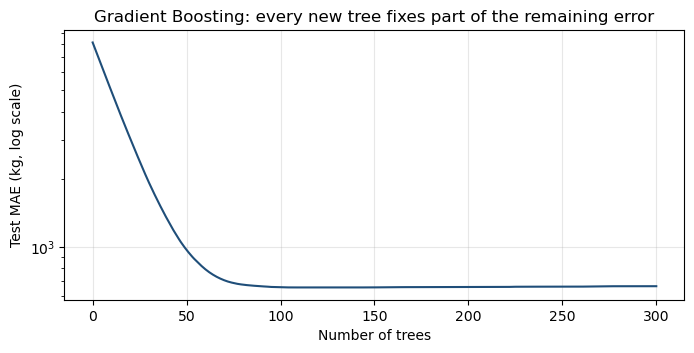

MAE with 0 trees (just the average): 8,163 kg  →  with 300 trees: 665 kg


In [11]:
import matplotlib.pyplot as plt
F_test = np.full(len(X_test), gb.start_value)
errors = [mae(y_test, F_test)]
for tree in gb.trees:
    F_test += gb.learning_rate * tree.predict(X_test)
    errors.append(mae(y_test, F_test))

plt.figure(figsize=(8, 3.5))
plt.plot(errors, color="#1f4e79")
plt.yscale("log"); plt.xlabel("Number of trees"); plt.ylabel("Test MAE (kg, log scale)")
plt.title("Gradient Boosting: every new tree fixes part of the remaining error")
plt.grid(alpha=.3); plt.show()
print(f"MAE with 0 trees (just the average): {errors[0]:,.0f} kg  →  with 300 trees: {errors[-1]:,.0f} kg")

---
## Part 8 · K-Fold (from scratch)

Stacking needs predictions from each base model on rows that the model **did not train on**. K-Fold gives us that:

1. Shuffle the training rows and cut them into **K = 5** equal parts ("folds").
2. For fold 1: train on folds 2-5, predict fold 1. For fold 2: train on folds 1, 3, 4, 5, predict fold 2. … and so on.
3. After 5 rounds, **every training row has a prediction made by a model that never saw it.**
   These are called **out-of-fold (OOF) predictions**.

```
Round 1: [TEST ] [train] [train] [train] [train]
Round 2: [train] [TEST ] [train] [train] [train]
Round 3: [train] [train] [TEST ] [train] [train]
Round 4: [train] [train] [train] [TEST ] [train]
Round 5: [train] [train] [train] [train] [TEST ]
```
**Shuffling is important:** our CSV is sorted by hectares. Without shuffling, one fold could contain all the 6-hectare farms, and the model trained on the other folds would never see a 6-hectare farm.

In [12]:
def my_kfold(n_rows, k=5, seed=0):
    rng = np.random.RandomState(seed)
    folds = np.array_split(rng.permutation(n_rows), k)   # shuffle, then cut into k nearly-equal parts
    for i in range(k):
        val_rows = folds[i]
        train_rows = np.concatenate([folds[j] for j in range(k) if j != i])
        yield train_rows, val_rows

for i, (tr, va) in enumerate(my_kfold(len(y_train))):
    print(f"Round {i + 1}: train on {len(tr)} rows, predict {len(va)} unseen rows")

Round 1: train on 1496 rows, predict 374 unseen rows
Round 2: train on 1496 rows, predict 374 unseen rows
Round 3: train on 1496 rows, predict 374 unseen rows
Round 4: train on 1496 rows, predict 374 unseen rows
Round 5: train on 1496 rows, predict 374 unseen rows


---
## Part 9 · The Stacking Regressor = our Hybrid model

Now we connect all the pieces. Our hybrid has **3 base models + 1 meta model**:

```
                ┌─ Gradient Boosting (depth 3, 300 trees, η=0.05) ──► p1 ─┐
Farm data X ───►├─ Gradient Boosting (depth 2, 400 trees, η=0.03) ──► p2 ─┼──► Positive Linear Regression ──► final yield
                └─ Random Forest (100 trees, min leaf 3) ──► p3 ─┘ final = b + w1·p1 + w2·p2 + w3·p3
```

### Training (`fit`), step by step
1. **Out-of-fold predictions:** with our 5-fold splitter, train each base model on 4 folds and predict the 5th fold.
   → we get a table **P** with 3 columns (p1, p2, p3) and one row for every training farm. Every value is an "unseen" prediction.
2. **Train the meta model** on (P → y). It learns **how much to trust each base model**: weights w1, w2, w3 ≥ 0.
   We train it on *unseen* predictions on purpose: if it saw predictions on rows the base models had memorised, it would trust them too much.
3. **Retrain the 3 base models on ALL the training data**, so the final base models are as strong as possible.

### Predicting (`predict`)
1. Each of the 3 final base models predicts the new farm → p1, p2, p3
2. Meta model: final = b + w1·p1 + w2·p2 + w3·p3

**About `make_model` (a "factory"):** we store *recipes* (functions that create a fresh, untrained model) instead of models, because we need a **brand-new** model for every fold and once more for the final fit.

In [13]:
class MyStackingRegressor:
    def __init__(self, base_recipes, k=5, seed=0):
        self.base_recipes = base_recipes          # list of (name, function that creates a fresh model)
        self.k, self.seed = k, seed

    def fit(self, X, y):
        n, m = len(y), len(self.base_recipes)
        P = np.zeros((n, m))                      # out-of-fold predictions, one column per base model

        # Step 1: out-of-fold predictions
        for fold, (tr, va) in enumerate(my_kfold(n, self.k, self.seed), start=1):
            for j, (name, make_model) in enumerate(self.base_recipes):
                model = make_model().fit(X[tr], y[tr])
                P[va, j] = model.predict(X[va])
            print(f"  fold {fold}/{self.k} done")
        self.oof_predictions_ = P

        # Step 2: meta model learns how much to trust each base model
        self.meta = MyPositiveLinearRegression().fit(P, y)

        # Step 3: final base models trained on ALL training rows
        self.final_bases = [make_model().fit(X, y) for name, make_model in self.base_recipes]
        return self

    def base_predictions(self, X):
        return np.column_stack([model.predict(X) for model in self.final_bases])

    def predict(self, X):
        return self.meta.predict(self.base_predictions(X))


recipes = [
    ("Gradient Boosting (depth 3)", lambda: MyGradientBoosting(n_trees=300, learning_rate=0.05, max_depth=3)),
    ("Gradient Boosting (depth 2)", lambda: MyGradientBoosting(n_trees=400, learning_rate=0.03, max_depth=2)),
    ("Random Forest",               lambda: MyRandomForest(n_trees=100, min_samples_leaf=3)),
]

start = time.time()
my_hybrid = MyStackingRegressor(recipes, k=5, seed=0).fit(X_train, y_train)
print(f"Hand-made hybrid trained in {time.time() - start:.0f} s")

  fold 1/5 done


  fold 2/5 done


  fold 3/5 done


  fold 4/5 done


  fold 5/5 done


Hand-made hybrid trained in 158 s


### What did the meta model learn? (how much it trusts each base model)

In [14]:
weights = pd.DataFrame({
    "Base model": [name for name, _ in recipes],
    "Weight (w)": my_hybrid.meta.coef_.round(3),
    "Share of trust": (my_hybrid.meta.coef_ / my_hybrid.meta.coef_.sum() * 100).round(1).astype(str) + " %",
})
import joblib
sk_meta = joblib.load("paddy_model.pkl")["model"].final_estimator_
weights["scikit-learn's weight"] = sk_meta.coef_.round(3)
print("Intercept b =", round(my_hybrid.meta.intercept_, 1), "kg  (scikit-learn:", round(sk_meta.intercept_, 1), "kg)")
weights

Intercept b = -7.9 kg  (scikit-learn: -10.4 kg)


,Base model,Weight (w),Share of trust,scikit-learn's weight
0,Gradient Boosting (depth 3),0.591,59.0 %,0.357
1,Gradient Boosting (depth 2),0.410,41.0 %,0.643
2,Random Forest,0.000,0.0 %,0.000


 **How to read this:** final yield = b + w1·p1 + w2·p2 + w3·p3. The weights add up to about 1, so the hybrid is basically a **smart weighted average** of the 3 base models, with the weights **learned from data** instead of guessed.

 **Why can a base model get weight 0?** The meta model gives a model weight only if it adds information the others don't already provide. If the Gradient Boosting models already capture everything the Random Forest knows, and are slightly more accurate, the best mix gives the Random Forest (almost) nothing. That isn't a bug: the meta model **automatically chooses** how to combine the models, which is exactly its job. The last column shows that scikit-learn's own stacking model made a very similar choice.

### Following one test farm through the hybrid model

In [15]:
i = 0
farm = X_test[i:i + 1]
p = my_hybrid.base_predictions(farm)[0]
b, w = my_hybrid.meta.intercept_, my_hybrid.meta.coef_

print("Farm:", ", ".join(f"{int(val)} ha" if name == "Hectares" else name.replace("_", " = ")
                         for name, val in zip(feature_names, X_test[i]) if val != 0))
for (name, _), pj in zip(recipes, p):
    print(f"  {name:<28} predicts {pj:>10,.0f} kg")
print(f"\n  final = {b:,.1f} + " + " + ".join(f"{wj:.3f}×{pj:,.0f}" for wj, pj in zip(w, p)))
print(f"        = {b + w @ p:,.0f} kg      (actual yield of this farm: {y_test[i]:,.0f} kg)")

Farm: 5 ha, Agriblock = Kurinjipadi, Variety = ponmani, Soil = alluvial, Nursery = wet
  Gradient Boosting (depth 3)  predicts     30,842 kg
  Gradient Boosting (depth 2)  predicts     30,847 kg
  Random Forest                predicts     30,479 kg

  final = -7.9 + 0.591×30,842 + 0.410×30,847 + 0.000×30,479
        = 30,847 kg      (actual yield of this farm: 31,555 kg)


---
## Part 10 · Does our hand-made hybrid really work? Comparison with scikit-learn

We test everything on the **same 468 hidden test farms** as the main notebook:
- our hand-made base models and hybrid,
- the scikit-learn hybrid saved by the main notebook (`paddy_model.pkl`), trained on the exact same 1,870 training rows.

In [16]:
import joblib
sk_bundle = joblib.load("paddy_model.pkl")
sk_hybrid = sk_bundle["model"]
X_test_df = pd.DataFrame(X_test, columns=feature_names).reindex(columns=sk_bundle["columns"], fill_value=0)

base_test_preds = my_hybrid.base_predictions(X_test)
rows = [report(f"Ours · {name}", y_test, base_test_preds[:, j]) for j, (name, _) in enumerate(recipes)]
rows.append(report("Ours · Linear Regression", y_test, lin.predict(X_test)))
rows.append(report("Ours · HYBRID (from scratch)", y_test, my_hybrid.predict(X_test)))
rows.append(report("scikit-learn · HYBRID", y_test, sk_hybrid.predict(X_test_df)))

comparison = pd.DataFrame(rows).sort_values("R2", ascending=False).reset_index(drop=True)
comparison.style.format({"R2": "{:.4f}", "MAE (kg)": "{:.0f}", "RMSE (kg)": "{:.0f}", "MAPE (%)": "{:.2f}"}) \
          .highlight_max(subset=["R2"], color="#cfe0f3").highlight_min(subset=["MAE (kg)", "MAPE (%)"], color="#cfe0f3")

,Model,R2,MAE (kg),RMSE (kg),MAPE (%)
0,Ours · Gradient Boosting (depth 2),0.9903,657,913,2.88
1,scikit-learn · HYBRID,0.9903,658,913,2.89
2,Ours · HYBRID (from scratch),0.9902,661,914,2.91
3,Ours · Gradient Boosting (depth 3),0.9902,665,917,2.93
4,Ours · Random Forest,0.9894,686,953,3.02
5,Ours · Linear Regression,0.9875,770,1033,3.66


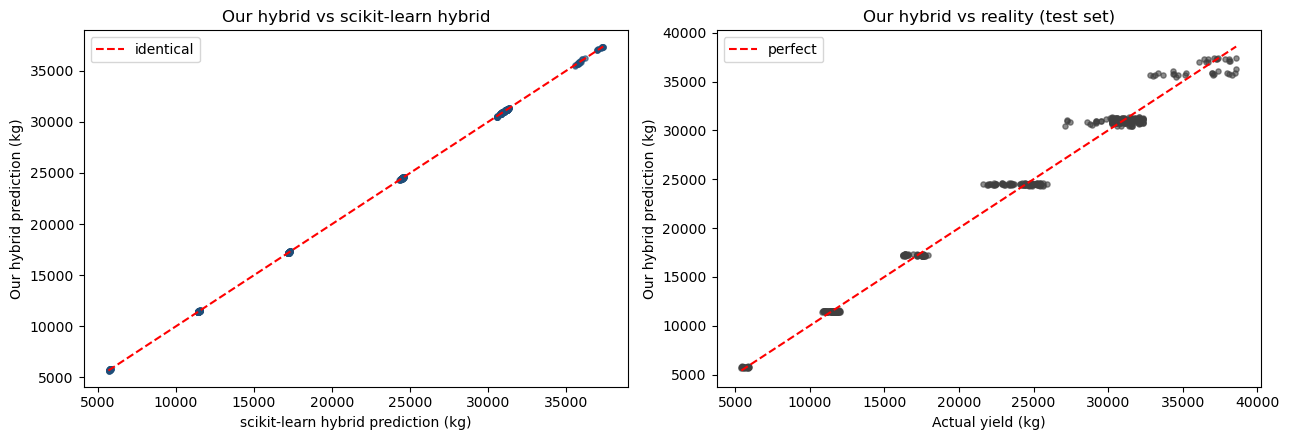

Average difference between our hybrid and scikit-learn's: 0.08 %  (max 0.44 %)


In [17]:
ours, theirs = my_hybrid.predict(X_test), sk_hybrid.predict(X_test_df)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(theirs, ours, s=14, alpha=.6, color="#1f4e79")
lim = [min(theirs.min(), ours.min()), max(theirs.max(), ours.max())]
ax[0].plot(lim, lim, "r--", label="identical")
ax[0].set_xlabel("scikit-learn hybrid prediction (kg)"); ax[0].set_ylabel("Our hybrid prediction (kg)")
ax[0].set_title("Our hybrid vs scikit-learn hybrid"); ax[0].legend()

ax[1].scatter(y_test, ours, s=14, alpha=.6, color="#404040")
ax[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", label="perfect")
ax[1].set_xlabel("Actual yield (kg)"); ax[1].set_ylabel("Our hybrid prediction (kg)")
ax[1].set_title("Our hybrid vs reality (test set)"); ax[1].legend()
plt.tight_layout(); plt.show()

diff = np.abs(ours - theirs) / theirs * 100
print(f"Average difference between our hybrid and scikit-learn's: {diff.mean():.2f} %  (max {diff.max():.2f} %)")

### Why are the results *almost* but not *exactly* the same?
Both versions follow the same algorithm, but a few small details differ:
- **Randomness:** our Random Forest picks different bootstrap rows than scikit-learn's (different random-number usage), and we use 100 trees instead of 300 to keep training quick.
- **Split rule:** scikit-learn's Gradient Boosting uses a slightly modified split score ("Friedman MSE"); we use plain SSE.
- **Folds:** the 5 folds inside stacking are shuffled with a different random generator.

These details change the predictions by only a fraction of a percent, and both reach **R² ≈ 0.99** with about **3% error**. This shows our hand-made hybrid is a correct implementation.

### Why is a single base model sometimes just as good as the hybrid here?
All the good models are already close to the best possible score for this data (some farms with identical conditions still have different yields, and no model can predict that random part). So the hybrid can't be much better. It is still a good final choice: it is **never worse** than its best member, and the meta model picks the mix automatically, so we don't have to guess which single model to trust.

---
## Viva cheat-sheet: explain it in your own words

**Q: What is a Decision Tree Regressor?**
A flow-chart of yes/no questions. At every node it tries all columns and cut-points and keeps the split with the lowest total squared error (SSE) of the two groups. A leaf predicts the average yield of the training farms that end up in it.

**Q: What is a Random Forest?**
Many decision trees, each trained on a bootstrap sample (random rows with replacement). The prediction is the average of all trees. Averaging cancels out individual trees' mistakes, so it is stable (low variance).

**Q: What is Gradient Boosting?**
Start from the average. Then add small trees one by one; each new tree is trained on the current residuals (mistakes), and only a fraction η (learning rate) of it is added. Many small corrections give an accurate model.

**Q: What is Stacking / your Hybrid model?**
Several base models (2 Gradient Boosting + 1 Random Forest) make predictions. A meta model (positive linear regression) is trained on their **out-of-fold** predictions and learns the best weights to combine them. Finally the base models are retrained on all training data.

**Q: Why out-of-fold predictions?**
If the meta model learned from predictions on rows the base models had already seen, those predictions would look unrealistically good, and the meta model would trust the wrong model. Out-of-fold predictions behave like predictions on new farms.

**Q: Why must the weights be positive?**
A negative weight would mean "do the opposite of a good model". That is not meaningful and is a sign of overfitting, so we force w ≥ 0.

**Q: Why shuffle the folds?**
The CSV is sorted by farm size. Without shuffling, a fold could contain only one farm size, and the models trained without it would never learn that size.

**Q: How do you know your code is correct?**
On the same train/test split, our hand-made hybrid gets almost the same R², MAE and predictions as scikit-learn's `StackingRegressor` (see Part 10).

**Q: What is the Normal Equation?**
w = (XᵀX)⁻¹Xᵀy, the direct formula for the least-squares weights of linear regression. We use the pseudo-inverse because our one-hot columns are linked (for example Soil_clay + Soil_alluvial = 1), which makes XᵀX non-invertible.